In [1]:
from pathlib import Path
import sys

# Find the project root from the notebook's working directory.
PROJECT_ROOT = Path.cwd().resolve()

# Run until found the (PROJECT_ROOT / "requirements.txt")
while not (PROJECT_ROOT / "requirements.txt").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Cannot find the project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Allow imports starting with "src".
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as vision

from src.evaluation.metrics import ClassificationMetrics
from src.models.cnn import CNN, Trainer, predict

In [3]:
SEED = 42
torch.manual_seed(SEED)

C1 = 32
C2 = 64
BATCH_SIZE = 128
EPOCHS = 30
LR = 0.001
ROTATION_DEGREES = 30
PATIENCE = 6

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


## HÀM PREDICT VỚI DATA LOADER

In [4]:
@torch.no_grad()
def predict_with_loader(model, data_loader, angle=0):
    """Trả về nhãn thật, nhãn dự đoán và độ tự tin cho từng ảnh."""
    model.eval()
    device = next(model.parameters()).device

    all_labels = []
    all_preds = []
    all_confidences = []

    for images, labels in data_loader:
        images = images.to(device)

        if angle != 0:
            images = vision.rotate(
                images,
                angle,
                interpolation=InterpolationMode.BILINEAR,
                fill=0,
            )

        logits = model(images)
        probabilities = logits.softmax(dim=1)
        confidences, predictions = probabilities.max(dim=1)

        all_labels.extend(labels.tolist())
        all_preds.extend(predictions.tolist())
        all_confidences.extend(confidences.tolist())

    return all_labels, all_preds, all_confidences

## HÀM LƯU TRỌNG SỐ

In [5]:
def save_weights(model, path=PROJECT_ROOT / "models" / "mnist_cnn.pth"):
    """Lưu trọng số vào thư mục models của dự án."""
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(model.state_dict(), path)
    print(f"Đã lưu trọng số vào {path}")

## ĐỌC VÀ TRANSFORM DỮ LIỆU 
- chuyển qua tensor
- chia cho 255 chuẩn hóa về [0,1]

In [6]:
transform = transforms.ToTensor()

full_train_data = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform, # chuyển thành tensor và / 255
)

test_data = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform,
)

# Chia 60.000 ảnh thành 50.000 ảnh train và 10.000 ảnh validation.
train_data, val_data = random_split(
    full_train_data,
    lengths=[50000, 10000],
    generator=torch.Generator().manual_seed(42),
)

# Tạo DataLoader.
train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

## HÀM PLOT CONFUSION MATRIX

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_confusion_matrix(metrics, normalize=False):
    """Vẽ ma trận nhầm lẫn; normalize=True hiển thị tỉ lệ theo từng nhãn thật."""
    cm, labels = metrics.get_confustion_matrix()

    if normalize:
        row_totals = cm.sum(axis=1, keepdims=True)
        cm_to_plot = np.divide(
            cm,
            row_totals,
            out=np.zeros_like(cm, dtype=float),
            where=row_totals != 0,
        )
        fmt = ".2f"
        title = "Ma trận nhầm lẫn chuẩn hóa"
    else:
        cm_to_plot = cm
        fmt = "d"
        title = "Ma trận nhầm lẫn"

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm_to_plot,
        annot=True,
        fmt=fmt,
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        square=True,
        cbar=True,
    )
    plt.xlabel("Nhãn dự đoán")
    plt.ylabel("Nhãn thật")
    plt.title(title)
    plt.tight_layout()
    plt.show()

## Train CNN

In [8]:
torch.manual_seed(SEED)
model = CNN(c1=C1, c2=C2)
trainer = Trainer(model, device, lr=LR)

num_params = sum(parameter.numel() for parameter in model.parameters())
print(f"Số tham số: {num_params:,}")

start_time = time.perf_counter()

history = trainer.fit(
    train_loader,
    val_loader,
    epochs=EPOCHS,
    patience=PATIENCE,
)

training_time = time.perf_counter() - start_time
print(f"Thời gian huấn luyện: {training_time:.2f} giây")

Số tham số: 421,642
Epoch 1/30 | Train loss: 0.0750, acc: 0.9784 | Val loss: 0.0879, acc: 0.9739
Epoch 2/30 | Train loss: 0.0426, acc: 0.9872 | Val loss: 0.0601, acc: 0.9826
Epoch 3/30 | Train loss: 0.0375, acc: 0.9887 | Val loss: 0.0592, acc: 0.9819
Epoch 4/30 | Train loss: 0.0243, acc: 0.9927 | Val loss: 0.0467, acc: 0.9861
Epoch 5/30 | Train loss: 0.0214, acc: 0.9930 | Val loss: 0.0492, acc: 0.9856
Epoch 6/30 | Train loss: 0.0150, acc: 0.9951 | Val loss: 0.0437, acc: 0.9868
Epoch 7/30 | Train loss: 0.0107, acc: 0.9966 | Val loss: 0.0416, acc: 0.9876
Epoch 8/30 | Train loss: 0.0145, acc: 0.9951 | Val loss: 0.0461, acc: 0.9870
Epoch 9/30 | Train loss: 0.0111, acc: 0.9964 | Val loss: 0.0476, acc: 0.9873
Epoch 10/30 | Train loss: 0.0081, acc: 0.9974 | Val loss: 0.0496, acc: 0.9869
Epoch 11/30 | Train loss: 0.0070, acc: 0.9978 | Val loss: 0.0487, acc: 0.9872
Epoch 12/30 | Train loss: 0.0110, acc: 0.9962 | Val loss: 0.0517, acc: 0.9874
Epoch 13/30 | Train loss: 0.0053, acc: 0.9983 | Val l

In [9]:
result = trainer.evaluate(test_loader, collect=True)

print(f"Test loss: {result['loss']:.4f}")
print(f"Test accuracy: {result['accuracy']:.4%}")

# Dự đoán một ảnh.
image, label = test_data[0]
digit, confidence = predict(model, image)

print(f"Nhãn thật: {label}")
print(f"Dự đoán: {digit}, xác suất: {confidence:.2%}")

Test loss: 0.0287
Test accuracy: 99.1300%
Nhãn thật: 7
Dự đoán: 7, xác suất: 100.00%


     Class  Precision     Recall         F1
         0      0.991      0.996      0.993 
         1      0.993      0.998      0.996 
         2      0.993      0.985      0.989 
         3      0.988      0.999      0.994 
         4      0.990      0.994      0.992 
         5      0.994      0.985      0.990 
         6      0.993      0.991      0.992 
         7      0.989      0.990      0.990 
         8      0.992      0.988      0.990 
         9      0.990      0.985      0.988 
 Macro avg      0.991      0.991      0.991 

Accuracy: 0.991


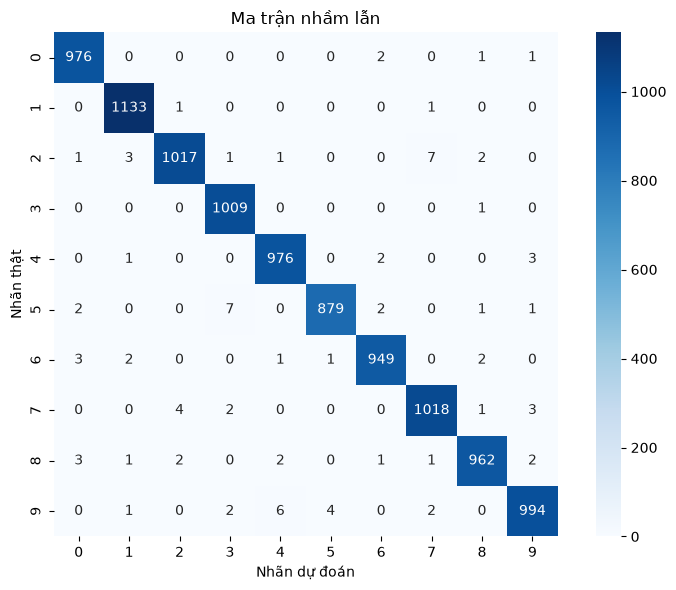

In [10]:
from src.evaluation.metrics import ClassificationMetrics
import numpy as np
# result lấy từ trainer.evaluate(test_loader, collect=True)
y_true = result["labels"].numpy()
y_pred = result["probs"].argmax(dim=1).numpy()

metrics = ClassificationMetrics(y_true=y_true,y_pred=y_pred, labels=np.arange(10))

metrics.report()
plot_confusion_matrix(metrics)

## LƯU TRỌNG SỐ

In [11]:
save_weights(model=model, path=PROJECT_ROOT / 'models' / 'mnist_cnn.pth')

Đã lưu trọng số vào /home/nguyenhaianh/Desktop/Classify_Number/models/mnist_cnn.pth


## TRAIN CNN KẾT HỢP TĂNG CƯỜNG DỮ LIỆU (XOAY HÌNH)

In [12]:
# Dùng đúng các chỉ số train đã chọn ở thí nghiệm gốc.
rotation_transform = transforms.Compose([
    transforms.RandomRotation(
        ROTATION_DEGREES,
        interpolation=InterpolationMode.BILINEAR,
        fill=0,
    ),
    transforms.ToTensor(),
])
rotated_mnist = datasets.MNIST(
    root="./data", train=True, transform=rotation_transform
)
rotated_train = Subset(rotated_mnist, train_data.indices)
rotated_loader = DataLoader(
    rotated_train, batch_size=BATCH_SIZE, shuffle=True
)

torch.manual_seed(SEED)
rotated_model = CNN(c1=C1, c2=C2)
rotated_trainer = Trainer(rotated_model, device, lr=LR)

start = time.perf_counter()
rotated_history = rotated_trainer.fit(
    rotated_loader, val_loader, epochs=EPOCHS, patience=PATIENCE
)
time_train_cnn_located = time.perf_counter() - start
save_weights(rotated_model, PROJECT_ROOT / "models" / "mnist_cnn_rotated.pth")


print(f"time train cnn located: {time_train_cnn_located:2f}")

Epoch 1/30 | Train loss: 0.1211, acc: 0.9638 | Val loss: 0.0892, acc: 0.9737
Epoch 2/30 | Train loss: 0.0813, acc: 0.9758 | Val loss: 0.0660, acc: 0.9806
Epoch 3/30 | Train loss: 0.0823, acc: 0.9741 | Val loss: 0.0724, acc: 0.9774
Epoch 4/30 | Train loss: 0.0560, acc: 0.9823 | Val loss: 0.0497, acc: 0.9841
Epoch 5/30 | Train loss: 0.0574, acc: 0.9821 | Val loss: 0.0563, acc: 0.9823
Epoch 6/30 | Train loss: 0.0475, acc: 0.9854 | Val loss: 0.0466, acc: 0.9870
Epoch 7/30 | Train loss: 0.0433, acc: 0.9866 | Val loss: 0.0473, acc: 0.9859
Epoch 8/30 | Train loss: 0.0390, acc: 0.9877 | Val loss: 0.0426, acc: 0.9871
Epoch 9/30 | Train loss: 0.0352, acc: 0.9884 | Val loss: 0.0410, acc: 0.9878
Epoch 10/30 | Train loss: 0.0312, acc: 0.9901 | Val loss: 0.0428, acc: 0.9883
Epoch 11/30 | Train loss: 0.0281, acc: 0.9915 | Val loss: 0.0377, acc: 0.9890
Epoch 12/30 | Train loss: 0.0261, acc: 0.9916 | Val loss: 0.0369, acc: 0.9894
Epoch 13/30 | Train loss: 0.0253, acc: 0.9919 | Val loss: 0.0371, acc: 0.

## So sánh trên cùng ảnh validation

Mỗi cột kết quả dùng cùng các ảnh, xoay ở một góc cố định. Góc 0° đo khả năng nhận diện ảnh gốc.

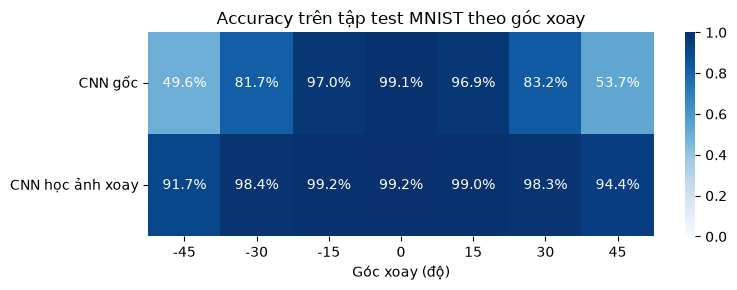

In [13]:
angles = [-45,-30, -15, 0, 15, 30, 45]

models = {
    "CNN gốc": model,
    "CNN học ảnh xoay": rotated_model,
}

scores = []
for candidate in models.values():
    row = []
    for angle in angles:
        y_true, y_pred, _ = predict_with_loader(
            candidate, test_loader, angle=angle
        )
        metrics = ClassificationMetrics(y_true, y_pred, labels=np.arange(10))
        row.append(metrics.evaluate()["accuracy"])
    scores.append(row)

plt.figure(figsize=(8, 3))

sns.heatmap(
    scores,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=angles,
    yticklabels=list(models),
)

plt.title("Accuracy trên tập test MNIST theo góc xoay")
plt.xlabel("Góc xoay (độ)")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Biểu đồ tốc độ học từng epoch của mô hình CNN và CNN với tăng cường dữ liệu

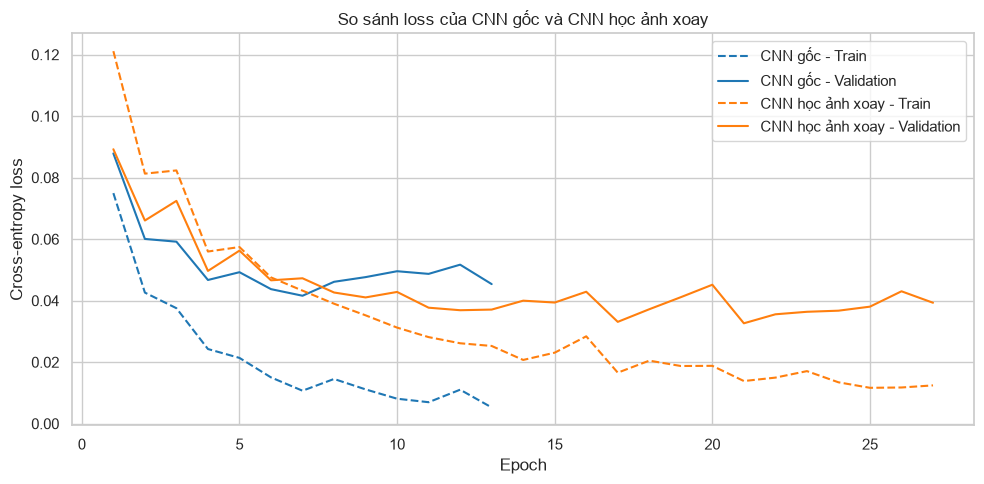

In [14]:
sns.set_theme(style="whitegrid")

experiments = [
    ("CNN gốc", history, "tab:blue"),
    ("CNN học ảnh xoay", rotated_history, "tab:orange"),
]

plt.figure(figsize=(10, 5))

for name, model_history, color in experiments:
    epochs = range(1, len(model_history["train_loss"]) + 1)

    sns.lineplot(
        x=epochs,
        y=model_history["train_loss"],
        label=f"{name} - Train",
        color=color,
        linestyle="--",
    )
    sns.lineplot(
        x=epochs,
        y=model_history["val_loss"],
        label=f"{name} - Validation",
        color=color,
        linestyle="-",
    )

plt.title("So sánh loss của CNN gốc và CNN học ảnh xoay")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.tight_layout()
plt.show()

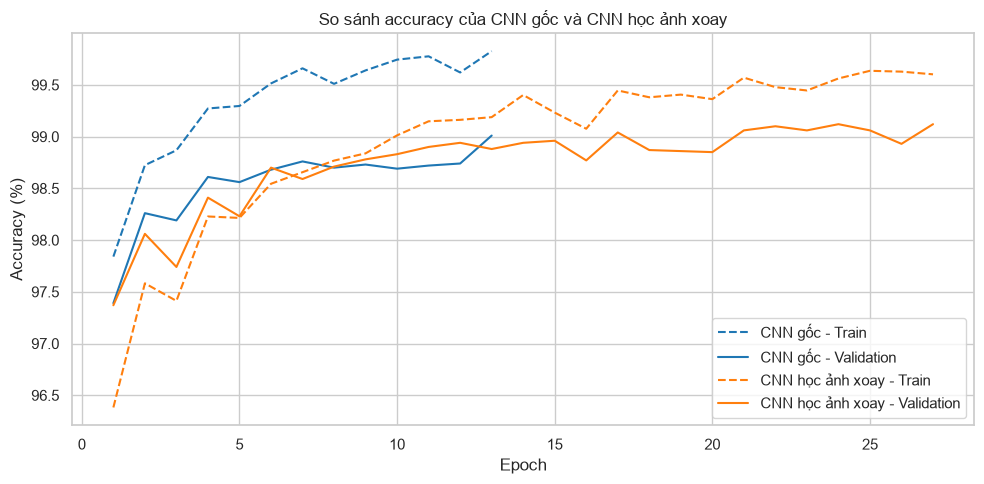

In [15]:
plt.figure(figsize=(10, 5))

for name, model_history, color in experiments:
    epochs = range(1, len(model_history["train_acc"]) + 1)

    train_accuracy = [value * 100 for value in model_history["train_acc"]]
    val_accuracy = [value * 100 for value in model_history["val_acc"]]

    sns.lineplot(
        x=epochs,
        y=train_accuracy,
        label=f"{name} - Train",
        color=color,
        linestyle="--",
    )
    sns.lineplot(
        x=epochs,
        y=val_accuracy,
        label=f"{name} - Validation",
        color=color,
        linestyle="-",
    )

plt.title("So sánh accuracy của CNN gốc và CNN học ảnh xoay")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.tight_layout()
plt.show()